# ⚡ Energy Consumption Clustering with K-Means
**Goal:** Group energy readings into similar groups (clusters) using *energy consumption* and *temperature*.

**What is K-Means?** It puts similar data points into K groups. Each group has a centre (centroid), and every point joins the nearest centre.

**Steps in this notebook:** 1 Load → 2 Understand → 3 EDA → 4 Clean → 5 Select features → 6 Scale → 7 Build → 8 Evaluate → 9 Save

## Step 0: Import libraries
These are the tools we need. Run this cell first.

In [1]:
import pandas as pd                      # tables (DataFrames)
import matplotlib.pyplot as plt          # graphs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib                            # to save the model

## Step 1: Data Collection
Read the CSV file into a table called `df`.

In [2]:
df = pd.read_csv('data/energy_data.csv')
df.head()      # show first 5 rows

,timestamp,location,energy_consumption,temperature
0,01-01-2023 00:00,Industrial,139.101364,33.820542
1,01-01-2023 01:00,Residential,247.109808,26.392602
2,01-01-2023 02:00,Industrial,233.934693,25.027439
3,01-01-2023 03:00,Industrial,243.013532,27.107712
4,01-01-2023 04:00,Residential,313.502582,27.326153


## Step 2: Data Understanding
How big is the data? What columns and types do we have?

In [3]:
print('Rows, Columns:', df.shape)
print()
print(df.dtypes)

Rows, Columns: (10000, 4)

timestamp                 str
location                  str
energy_consumption    float64
temperature           float64
dtype: object


In [4]:
df.describe()   # min, max, average of numeric columns

,energy_consumption,temperature
count,10000.000000,10000.000000
mean,275.404802,24.991026
std,129.290724,5.783142
min,50.053390,15.000186
25%,165.525565,19.971860
50%,275.677604,24.963709
75%,385.844981,30.000277
max,499.951700,34.997821


## Step 3: EDA (Exploratory Data Analysis)
Let's look at the data using simple graphs.

**The key graph – Temperature vs Energy:** each dot is one reading. K-Means will group these dots, so this is the most useful graph to look at first.

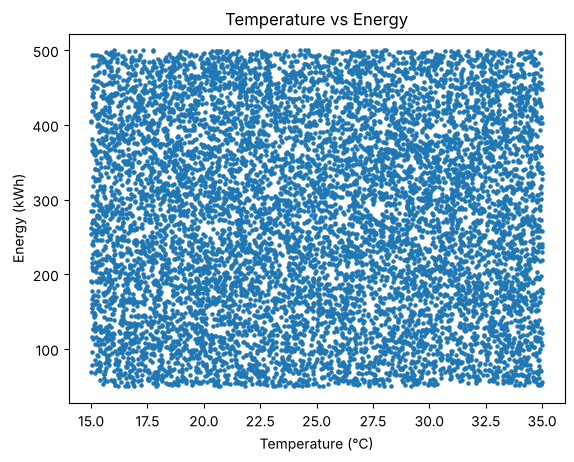

In [5]:
plt.scatter(df['temperature'], df['energy_consumption'], s=5)
plt.title('Temperature vs Energy')
plt.xlabel('Temperature (°C)')
plt.ylabel('Energy (kWh)')
plt.show()

💡 **Insights from this graph**
- Dots fill the whole rectangle evenly → energy (50–500 kWh) and temperature (15–35 °C) are both spread uniformly, with no spikes or extreme values.
- No upward or downward trend → temperature does **not** affect energy use (correlation ≈ 0.004).
- Location (Commercial / Industrial / Residential) also makes no difference: all three average ≈ 275 kWh.
- So K-Means will cut the area into simple blocks: low/high energy × cool/hot weather.

⚠️ This data looks synthetic. Real data usually shows stronger patterns.

## Step 4: Data Preprocessing
Check missing values and duplicates, and look for outliers (extreme values).

In [6]:
print('Missing values:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

Missing values:
timestamp             0
location              0
energy_consumption    0
temperature           0
dtype: int64

Duplicate rows: 0


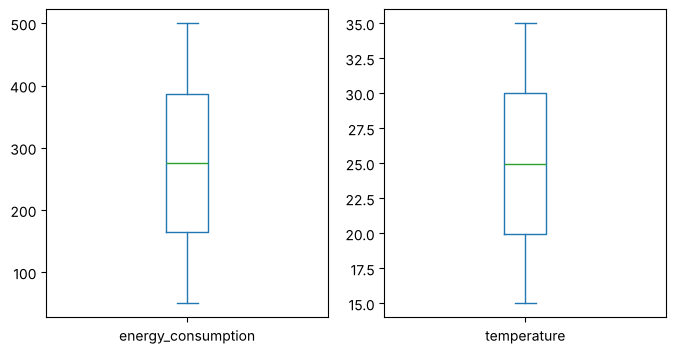

In [7]:
# Box plot: dots outside the box would be outliers
df[['energy_consumption', 'temperature']].plot(kind='box', subplots=True, figsize=(8, 4))
plt.show()

💡 **Insight:** No dots outside the boxes, so there are **no outliers**. No missing values or duplicates either, so the data is clean and we do not remove anything.

In [8]:
# Remove duplicates and missing rows (none here, but good practice)
df = df.drop_duplicates()
df = df.dropna()
print('Rows after cleaning:', len(df))

Rows after cleaning: 10000


## Step 5: Feature Selection
K-Means works only with **numbers**, so we pick two numeric columns.

In [9]:
X = df[['energy_consumption', 'temperature']]
X.head()

,energy_consumption,temperature
0,139.101364,33.820542
1,247.109808,26.392602
2,233.934693,25.027439
3,243.013532,27.107712
4,313.502582,27.326153


## Step 6: Feature Scaling
Energy goes up to 500 but temperature only up to 35. Big numbers would dominate, so we bring both to the same scale using `StandardScaler`.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-1.0542926   1.52684411]
 [-0.21885876  0.24236751]
 [-0.32076688  0.0062966 ]
 [-0.25054303  0.36602793]
 [ 0.29468228  0.40380182]]


## Step 7: Model Building
**How many clusters (K)?** We try K = 2 to 10 and measure:
- **WCSS** – how tight the clusters are (lower = better)
- **Silhouette score** – how well separated they are (higher = better)

In [11]:
wcss_list = []
silhouette_list = []
k_values = [2, 3, 4, 5, 6, 7, 8, 9, 10]

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, model.labels_))

**Elbow Method:** pick K where the line bends like an elbow.

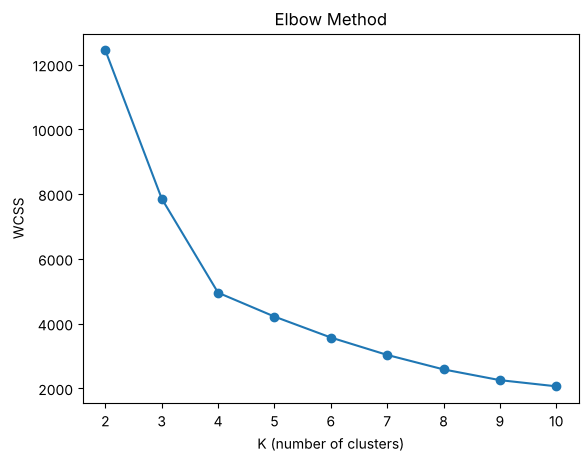

In [12]:
plt.plot(k_values, wcss_list, marker='o')
plt.title('Elbow Method')
plt.xlabel('K (number of clusters)')
plt.ylabel('WCSS')
plt.show()

**Silhouette Score:** pick the K with the highest value.

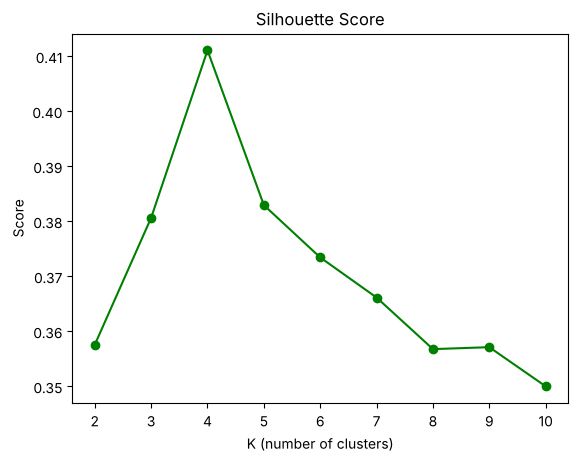

Best K = 4


In [13]:
plt.plot(k_values, silhouette_list, marker='o', color='green')
plt.title('Silhouette Score')
plt.xlabel('K (number of clusters)')
plt.ylabel('Score')
plt.show()

best_k = k_values[silhouette_list.index(max(silhouette_list))]
print('Best K =', best_k)

Now train the final model with the best K.

In [14]:
model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster'] = model.fit_predict(X_scaled)
df.head()

,timestamp,location,energy_consumption,temperature,cluster
0,01-01-2023 00:00,Industrial,139.101364,33.820542,0
1,01-01-2023 01:00,Residential,247.109808,26.392602,0
2,01-01-2023 02:00,Industrial,233.934693,25.027439,3
3,01-01-2023 03:00,Industrial,243.013532,27.107712,0
4,01-01-2023 04:00,Residential,313.502582,27.326153,1


## Step 8: Model Evaluation

In [15]:
print('WCSS       :', round(model.inertia_, 2))
print('Silhouette :', round(silhouette_score(X_scaled, df['cluster']), 3))

WCSS       : 4953.02


Silhouette : 0.411


**Cluster graph:** each colour is a cluster. Red ✖ marks are the centres.

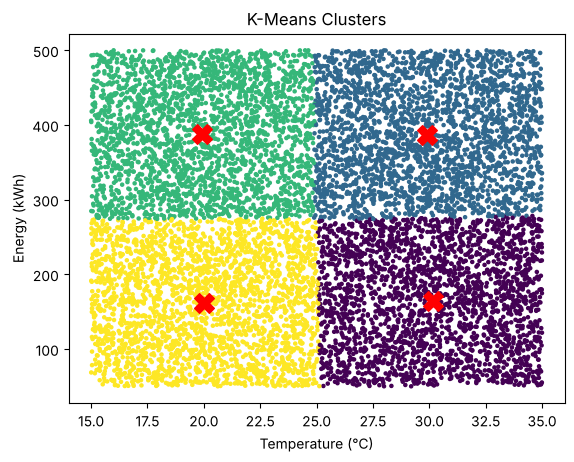

In [16]:
plt.scatter(df['temperature'], df['energy_consumption'], c=df['cluster'], s=5, cmap='viridis')

# Convert centres back to original units
centres = scaler.inverse_transform(model.cluster_centers_)
plt.scatter(centres[:, 1], centres[:, 0], c='red', marker='X', s=200)

plt.title('K-Means Clusters')
plt.xlabel('Temperature (°C)')
plt.ylabel('Energy (kWh)')
plt.show()

**Cluster summary:** average energy and temperature of each cluster.

In [17]:
df.groupby('cluster')[['energy_consumption', 'temperature']].mean().round(1)

,energy_consumption,temperature
cluster,,
0,164.7,30.2
1,386.6,29.9
2,387.3,19.9
3,161.8,20.0


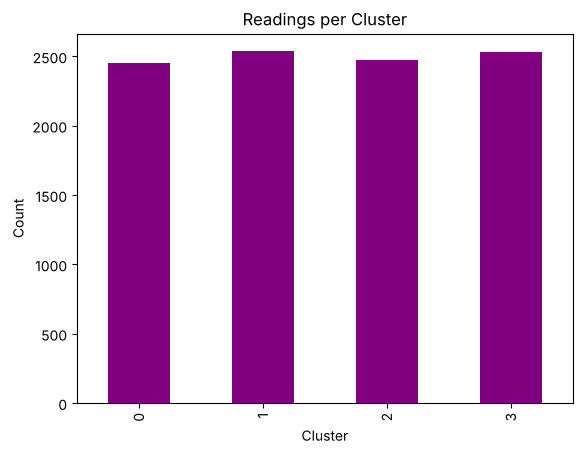

In [18]:
df['cluster'].value_counts().sort_index().plot(kind='bar', color='purple')
plt.title('Readings per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.show()

**Meaning:** each cluster = a mix of *low/high energy* and *cool/hot temperature*.

## Step 9: Save the Model
Save the model and scaler so the web app can use them later.

In [19]:
joblib.dump(model, 'model/kmeans_notebook.joblib')
joblib.dump(scaler, 'model/scaler_notebook.joblib')
print('Saved!')

Saved!


**Try it:** predict the cluster of a new reading.

In [20]:
new = pd.DataFrame([[400, 32]], columns=['energy_consumption', 'temperature'])
print('Cluster:', model.predict(scaler.transform(new))[0])

Cluster: 1


## Next: Steps 10–14
Web app (`app.py`) → test locally → GitHub → Streamlit Cloud → monitor. See `README.md`.